# Modeling — Diabetes Risk Screening

This notebook compares models for predicting whether a person has **prediabetes or diabetes**, based on the
BRFSS 2015 survey data explored in `EDA.ipynb`. It is step 1 of the plan in `PROJECT_PLAN.md`; decisions are
recorded in `DECISIONS.md`.

> **Purpose:** a **screening tool** that finds candidates for an actual diabetes test (blood glucose / HbA1c).
> It is **not a diagnosis**.

**What we compare**

| Model | Why |
|---|---|
| Dummy classifier | The floor: always predicts "no diabetes" |
| Logistic regression | Simple, explainable linear baseline |
| CatBoost | Main candidate: gradient-boosted trees |

**What we test along the way**
1. **Balancing** the training data: none vs. class weights vs. 50/50 downsampling.
2. **Duplicates:** do the ~24k duplicate rows inflate the scores, and does removing them help?
3. **CatBoost categorical features:** treat `GenHlth`, `Age`, `Education`, `Income` as categories or as ordered numbers?
4. **Threshold:** which precision do we get at different recall levels?

> **Runtime:** about 10 minutes, mostly CatBoost cross-validation.

## 1. Setup

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_recall_curve, roc_curve, accuracy_score,
                             precision_score, recall_score, f1_score)
from sklearn.calibration import calibration_curve
from catboost import CatBoostClassifier

SEED = 42
N_FOLDS = 5
plt.rcParams["figure.figsize"] = (9, 4)

## 2. Load data and create the target

Same file and loading as in `EDA.ipynb`. The three-class `Diabetes_012` is turned into a **yes/no target**:
`0` = no diabetes, `1` = prediabetes **or** diabetes. Prediabetes alone is only 1.8% of the rows — too rare to
predict as its own class.

In [2]:
csv_path = Path("../../data/raw_data/diabetes_012_health_indicators_BRFSS2015.csv")
df = pd.read_csv(csv_path).astype(int)

y = (df["Diabetes_012"] > 0).astype(int).rename("diabetes")
X = df.drop(columns="Diabetes_012")

print(f"Rows: {len(df):,}, features: {X.shape[1]}")
print(f"Share with prediabetes or diabetes: {y.mean():.1%}")

Rows: 253,680, features: 21
Share with prediabetes or diabetes: 15.8%


### Feature groups

Logistic regression needs different preprocessing per feature type; tree models (CatBoost) do not.

In [3]:
numeric_cols = ["BMI", "MentHlth", "PhysHlth"]                   # real numbers -> scaled
ordinal_cols = ["GenHlth", "Age", "Education", "Income"]         # ordered codes -> one-hot for LR
binary_cols = [c for c in X.columns if c not in numeric_cols + ordinal_cols]  # 0/1 flags -> as-is
print("Binary:", binary_cols)

Binary: ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']


## 3. Train/test split

We split **once**: 80% training, 20% test, **stratified** so both parts keep the real share of diabetics
(~14%). The test set is put aside and used **only once**, at the very end (section 9).

All comparisons before that use **5-fold cross-validation on the training part**.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print(f"Train: {len(X_train):,} rows ({y_train.mean():.1%} positive)")
print(f"Test:  {len(X_test):,} rows ({y_test.mean():.1%} positive)")

Train: 202,944 rows (15.8% positive)
Test:  50,736 rows (15.8% positive)


The split is saved to `data/splits/train_test_split.csv` (row number in the raw CSV → `train` / `test`), so the
AutoML benchmark (`AutoML.ipynb`, separate environment) uses **exactly** the same rows.

In [5]:
split_path = Path("../../data/splits/train_test_split.csv")
split_path.parent.mkdir(parents=True, exist_ok=True)
split = pd.Series("train", index=X.index, name="split")
split.loc[X_test.index] = "test"
split.rename_axis("row").to_csv(split_path)
print(split.value_counts().to_dict(), "->", split_path)

{'train': 202944, 'test': 50736} -> ..\..\data\splits\train_test_split.csv


## 4. Helpers: models, balancing, cross-validation

**Balancing options** (applied to the **training part of each fold only** — validation and test data always keep
the real class ratio):

| Option | What it does |
|---|---|
| `none` | Train on the data as it is |
| `weights` | Keep all rows, but give each diabetic row more weight so both classes count equally |
| `downsample` | Randomly drop "no diabetes" rows until the training part is 50/50 |

**Metrics** — because the decision threshold is chosen later, we compare models with threshold-free metrics:

| Metric | Meaning |
|---|---|
| ROC-AUC | How well the model ranks diabetics above non-diabetics (0.5 = random, 1 = perfect) |
| PR-AUC | Same idea, but focused on the rare class; baseline = share of diabetics (~0.16) |
| Precision @ 80% recall | If we set the threshold so 80% of diabetics are caught: what share of flagged people actually have diabetes? |
| Brier score | How accurate the predicted **probabilities** are (lower is better) |

In [6]:
def make_logreg(class_weight=None):
    pre = ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("ord", OneHotEncoder(handle_unknown="ignore"), ordinal_cols),
        ("bin", "passthrough", binary_cols),
    ])
    return make_pipeline(pre, LogisticRegression(max_iter=2000, class_weight=class_weight))


def make_catboost(class_weights=None, cat_features=None):
    return CatBoostClassifier(iterations=500, learning_rate=0.1, depth=6, random_seed=SEED, verbose=0,
                              auto_class_weights=class_weights, cat_features=cat_features)


def make_model(name, balancing):
    if name == "logreg":
        return make_logreg("balanced" if balancing == "weights" else None)
    if name == "catboost":
        return make_catboost("Balanced" if balancing == "weights" else None)
    raise ValueError(name)


def downsample(X_part, y_part, seed=SEED):
    """Randomly drop majority-class rows until both classes are equally large."""
    pos = y_part[y_part == 1].index
    neg = y_part[y_part == 0].sample(n=len(pos), random_state=seed).index
    keep = pos.union(neg)
    return X_part.loc[keep], y_part.loc[keep]


def precision_at_recall(y_true, proba, target_recall=0.80):
    precision, recall, _ = precision_recall_curve(y_true, proba)
    return precision[recall >= target_recall].max()


def score(y_true, proba):
    return {
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "Precision@80%recall": precision_at_recall(y_true, proba),
        "Brier": brier_score_loss(y_true, proba),
    }


def cross_validate(name, balancing, X_cv=None, y_cv=None, splitter=None, groups=None, train_filter=None):
    """5-fold CV. Returns out-of-fold probabilities and the mean scores."""
    X_cv = X_train if X_cv is None else X_cv
    y_cv = y_train if y_cv is None else y_cv
    splitter = splitter or StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
    oof = pd.Series(np.nan, index=y_cv.index)
    start = time.time()
    for tr_idx, va_idx in splitter.split(X_cv, y_cv, groups):
        X_tr, y_tr = X_cv.iloc[tr_idx], y_cv.iloc[tr_idx]
        if train_filter is not None:
            X_tr, y_tr = train_filter(X_tr, y_tr)
        if balancing == "downsample":
            X_tr, y_tr = downsample(X_tr, y_tr)
        model = make_model(name, balancing).fit(X_tr, y_tr)
        oof.iloc[va_idx] = model.predict_proba(X_cv.iloc[va_idx])[:, 1]
    result = {"model": name, "balancing": balancing, **score(y_cv, oof),
              "seconds": round(time.time() - start, 1)}
    return oof, result

## 5. Baseline: dummy classifier

A model that always says "no diabetes". Its accuracy shows why **accuracy is the wrong metric** here.

In [7]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Dummy accuracy on the training data: {accuracy_score(y_train, dummy.predict(X_train)):.1%}")
print("Dummy ROC-AUC: 0.5 (it cannot rank anyone above anyone else)")
print(f"Dummy recall: 0% (it never flags anyone) — useless for screening")

Dummy accuracy on the training data: 84.2%
Dummy ROC-AUC: 0.5 (it cannot rank anyone above anyone else)
Dummy recall: 0% (it never flags anyone) — useless for screening


## 6. Logistic regression vs. CatBoost × balancing options

Six combinations, each with 5-fold cross-validation on the training data.

In [8]:
results, oof_preds = [], {}
for name in ["logreg", "catboost"]:
    for balancing in ["none", "weights", "downsample"]:
        oof, res = cross_validate(name, balancing)
        oof_preds[(name, balancing)] = oof
        results.append(res)
        print(f"{name:9s} {balancing:10s} ROC-AUC {res['ROC-AUC']:.4f}  ({res['seconds']} s)")

cv_results = pd.DataFrame(results).set_index(["model", "balancing"])
display(cv_results.round(4))

logreg    none       ROC-AUC 0.8192  (4.4 s)


logreg    weights    ROC-AUC 0.8197  (3.8 s)


logreg    downsample ROC-AUC 0.8196  (1.5 s)


catboost  none       ROC-AUC 0.8244  (41.8 s)


catboost  weights    ROC-AUC 0.8235  (48.5 s)


catboost  downsample ROC-AUC 0.8221  (30.3 s)


ROC-AUC  PR-AUC  Precision@80%recall   Brier  seconds
model    balancing                                                        
logreg   none         0.8192  0.4388               0.3243  0.1076      4.4
         weights      0.8197  0.4368               0.3259  0.1783      3.8
         downsample   0.8196  0.4370               0.3254  0.1785      1.5
catboost none         0.8244  0.4546               0.3300  0.1062     41.8
         weights      0.8235  0.4573               0.3280  0.1739     48.5
         downsample   0.8221  0.4459               0.3274  0.1795     30.3

### Interpreting the comparison

- **ROC-AUC / PR-AUC / Precision@80% recall** measure how well a model *separates* the classes. Balancing barely
  changes these: it shifts the scores up but doesn't reorder people much.
- **Brier score** measures whether the probabilities are *honest*. Balancing (weights or downsampling) makes the
  model **overestimate** risk, because it was trained as if half of all people had diabetes. The calibration plot
  below shows this.

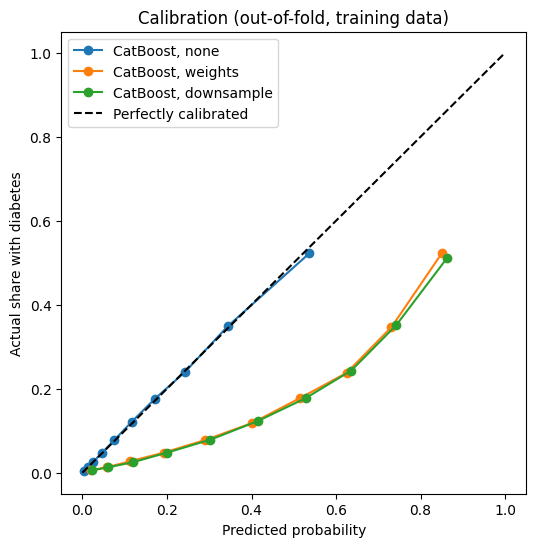

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
for balancing in ["none", "weights", "downsample"]:
    frac_pos, mean_pred = calibration_curve(y_train, oof_preds[("catboost", balancing)], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=f"CatBoost, {balancing}")
ax.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
ax.set_xlabel("Predicted probability")
ax.set_ylabel("Actual share with diabetes")
ax.set_title("Calibration (out-of-fold, training data)")
ax.legend()
plt.show()

## 7. Duplicates

The data has ~24k duplicate rows. Two questions:

1. **Do duplicates inflate the scores?** If identical rows land in both the training and validation fold, the
   model may "recognise" them. We test this with **grouped** cross-validation: identical rows always stay in the
   same fold.
2. **Does removing duplicates from the training data help?** We drop duplicates from each training fold, but still
   evaluate on the full validation fold (real data contains duplicates too).

Both tests use CatBoost without balancing; compare with the `catboost / none` row above.

In [10]:
row_groups = X_train.astype(str).agg("|".join, axis=1).astype("category").cat.codes  # same answers -> same group
dup_results = [cv_results.loc[("catboost", "none")].rename("standard CV (keep duplicates)")]

_, res = cross_validate("catboost", "none",
                        splitter=StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED), groups=row_groups)
dup_results.append(pd.Series(res).drop(["model", "balancing"]).rename("grouped CV (duplicates never split)"))

def drop_duplicate_rows(X_part, y_part):
    keep = ~pd.concat([X_part, y_part], axis=1).duplicated()
    return X_part[keep], y_part[keep]

_, res = cross_validate("catboost", "none", train_filter=drop_duplicate_rows)
dup_results.append(pd.Series(res).drop(["model", "balancing"]).rename("duplicates removed from training"))

display(pd.DataFrame(dup_results)[["ROC-AUC", "PR-AUC", "Precision@80%recall", "Brier"]].astype(float).round(4))

,ROC-AUC,PR-AUC,Precision@80%recall,Brier
standard CV (keep duplicates),0.8244,0.4546,0.3300,0.1062
grouped CV (duplicates never split),0.8248,0.4564,0.3297,0.1061
duplicates removed from training,0.8238,0.4537,0.3291,0.1063


## 8. CatBoost: categorical vs. numeric ordinal features

CatBoost can treat `GenHlth`, `Age`, `Education` and `Income` as **categories** (its special feature) or as
**ordered numbers** (default above). Since these codes have a natural order (age group 9 is older than 8), numbers
may work just as well. Because categorical mode is much slower, we compare on **one** training/validation split
(the first CV fold) instead of all five.

In [11]:
tr_idx, va_idx = next(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X_train, y_train))
X_tr, X_va, y_tr, y_va = X_train.iloc[tr_idx], X_train.iloc[va_idx], y_train.iloc[tr_idx], y_train.iloc[va_idx]

cat_results = {}
for label, cats in [("numeric (ordered numbers)", None), ("categorical", ordinal_cols)]:
    start = time.time()
    model = make_catboost(cat_features=cats).fit(X_tr, y_tr)
    cat_results[label] = {**score(y_va, model.predict_proba(X_va)[:, 1]), "seconds": round(time.time() - start, 1)}

display(pd.DataFrame(cat_results).T.round(4))

,ROC-AUC,PR-AUC,Precision@80%recall,Brier,seconds
numeric (ordered numbers),0.8217,0.4524,0.3257,0.1067,9.2
categorical,0.8227,0.4552,0.3266,0.1065,97.7


## 9. Threshold: how many diabetics can we catch, and at what cost?

For screening we choose the threshold by **recall** (share of diabetics caught). The table shows, for different
recall targets, the **precision** (share of flagged people who really have diabetes) and the share of all people
who would be flagged — using the out-of-fold predictions of both models (no balancing).

The final recall target is a **decision for the project team** (see `DECISIONS.md`).

In [12]:
def threshold_table(y_true, proba, targets=(0.60, 0.70, 0.75, 0.80, 0.85, 0.90)):
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    rows = []
    for t in targets:
        i = np.where(recall[:-1] >= t)[0].max()      # highest threshold that still reaches the recall target
        thr = thresholds[i]
        flagged = proba >= thr
        rows.append({"recall target": f"{t:.0%}", "threshold": round(thr, 3),
                     "recall": round(recall_score(y_true, flagged), 3),
                     "precision": round(precision_score(y_true, flagged), 3),
                     "share flagged": round(flagged.mean(), 3)})
    return pd.DataFrame(rows).set_index("recall target")

for name in ["logreg", "catboost"]:
    print(name)
    display(threshold_table(y_train, oof_preds[(name, "none")]))

logreg


,threshold,recall,precision,share flagged
recall target,,,,
60%,0.247,0.60,0.405,0.233
70%,0.195,0.70,0.367,0.301
75%,0.168,0.75,0.345,0.343
80%,0.143,0.80,0.324,0.389
85%,0.116,0.85,0.299,0.447
90%,0.089,0.90,0.273,0.519


catboost


,threshold,recall,precision,share flagged
recall target,,,,
60%,0.262,0.60,0.416,0.227
70%,0.206,0.70,0.372,0.296
75%,0.179,0.75,0.352,0.336
80%,0.151,0.80,0.330,0.382
85%,0.122,0.85,0.306,0.437
90%,0.089,0.90,0.277,0.511


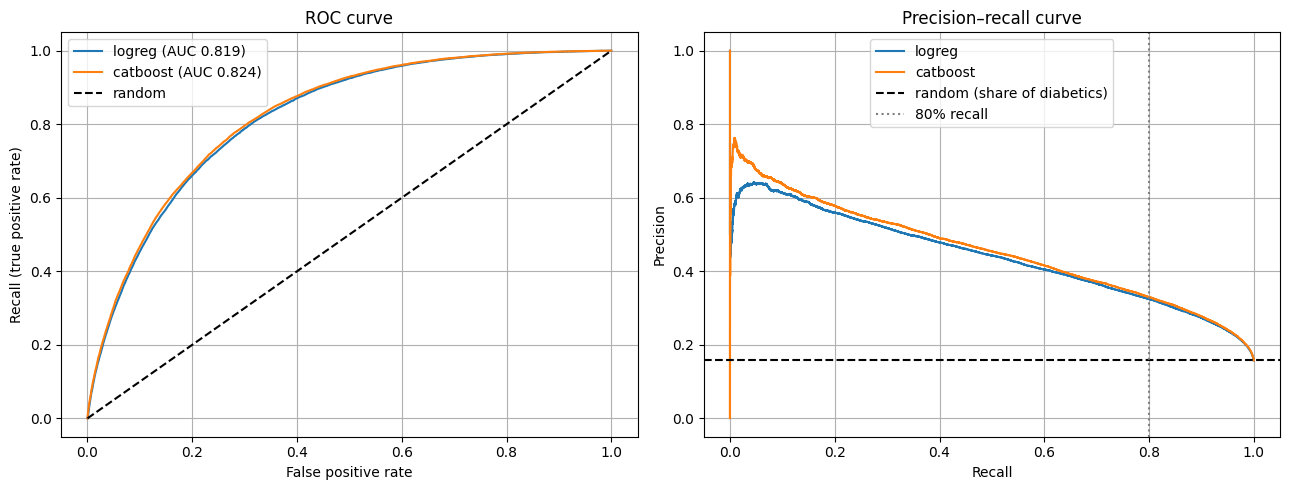

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in ["logreg", "catboost"]:
    proba = oof_preds[(name, "none")]
    fpr, tpr, _ = roc_curve(y_train, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_train, proba):.3f})")
    precision, recall, _ = precision_recall_curve(y_train, proba)
    axes[1].plot(recall, precision, label=name)
axes[0].plot([0, 1], [0, 1], "k--", label="random")
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="Recall (true positive rate)")
axes[1].axhline(y_train.mean(), color="k", ls="--", label="random (share of diabetics)")
axes[1].axvline(0.80, color="grey", ls=":", label="80% recall")
axes[1].set(title="Precision–recall curve", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend(); ax.grid(True)
plt.tight_layout()
plt.show()

## 10. Final check on the test set

Now — and only now — we use the test set. Both models are trained on the **full training data** (no balancing)
and evaluated once. The threshold is the one that gave **80% recall** in cross-validation (a working assumption
until the recall target is decided).

In [14]:
final_models = {
    "logreg": make_logreg().fit(X_train, y_train),
    "catboost": make_catboost().fit(X_train, y_train),
}

test_rows = []
for name, model in final_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_train, oof_preds[(name, "none")])
    thr = thresholds[np.where(recall[:-1] >= 0.80)[0].max()]   # threshold chosen on CV, not on the test set
    flagged = proba >= thr
    test_rows.append({"model": name, **score(y_test, proba), "threshold": thr,
                      "recall": recall_score(y_test, flagged), "precision": precision_score(y_test, flagged),
                      "F1": f1_score(y_test, flagged), "accuracy": accuracy_score(y_test, flagged),
                      "share flagged": flagged.mean()})

test_rows.append({"model": "dummy", "ROC-AUC": 0.5, "recall": 0.0,
                  "accuracy": accuracy_score(y_test, dummy.predict(X_test))})
test_results = pd.DataFrame(test_rows).set_index("model")
display(test_results.round(4))

,ROC-AUC,PR-AUC,Precision@80%recall,Brier,threshold,recall,precision,F1,accuracy,share flagged
model,,,,,,,,,,
logreg,0.8190,0.4421,0.3219,0.1075,0.1432,0.7944,0.3237,0.4600,0.7061,0.3867
catboost,0.8247,0.4633,0.3291,0.1057,0.1508,0.7961,0.3300,0.4666,0.7132,0.3801
dummy,0.5000,NaN,NaN,NaN,NaN,0.0000,NaN,NaN,0.8424,NaN


## 11. What drives the predictions?

**CatBoost feature importance** shows how much each feature contributes to the predictions. **Logistic regression
coefficients** show the direction: positive = higher risk.

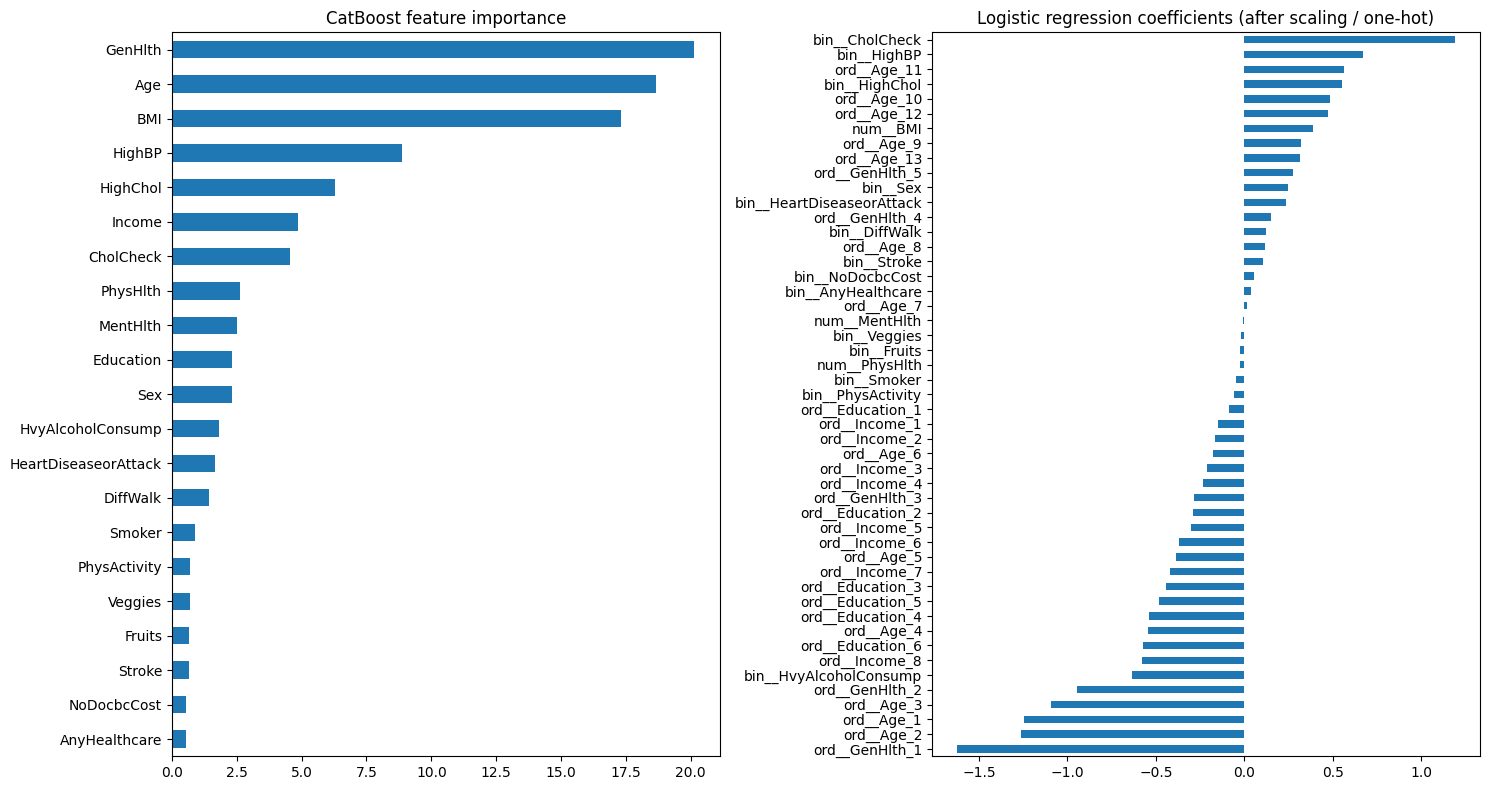

In [15]:
cb_importance = pd.Series(final_models["catboost"].get_feature_importance(), index=X_train.columns).sort_values()

lr = final_models["logreg"]
lr_coef = pd.Series(lr[-1].coef_[0], index=lr[0].get_feature_names_out()).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
cb_importance.plot.barh(ax=axes[0], title="CatBoost feature importance")
lr_coef.plot.barh(ax=axes[1], title="Logistic regression coefficients (after scaling / one-hot)")
plt.tight_layout()
plt.show()

## 12. Conclusions

Results from the run on 2026-11-17 (decisions D-17 to D-23 in `DECISIONS.md`):

1. **Both models clearly beat the dummy baseline.** The dummy is 84% accurate but catches nobody.
2. **CatBoost is slightly better than logistic regression** on every metric (test set: ROC-AUC 0.825 vs. 0.819,
   precision at ~80% recall 33.0% vs. 32.4%). The gap is small, as expected for this data. **CatBoost goes forward**
   as the model AutoML must beat (D-22).
3. **No balancing** (D-19). Class weights and 50/50 downsampling did not improve the ranking (ROC-AUC), but made the
   predicted probabilities much worse (Brier 0.17–0.18 vs. 0.106). The recall target is reached with the
   threshold instead, which keeps the probabilities honest for the UI.
4. **Duplicates are kept** (D-17). Grouped CV and removing duplicates changed ROC-AUC by less than 0.001.
5. **Ordinal codes as numbers** for CatBoost (D-20). Categorical mode was 8× slower for a negligible gain.
6. **Recall target 80%** (D-23). CatBoost then flags ~38% of people, and ~1 in 3 of them has diabetes. On the test
   set this held: 79.6% recall at 33.0% precision.
7. The test-set scores match cross-validation closely, so the results are not a lucky split.

**Next step:** AutoML benchmark on the same split (step 2 in `PROJECT_PLAN.md`).